# SWYNEX Final Project: Titanic Survival — End-to-End Data Science Case Study

This notebook combines all four stages of the SWYNEX Data Science internship into one documented project:
**Problem Statement → Data Preparation → Exploratory Data Analysis → Modeling → Conclusions.**

## 1. Problem Statement

**Business question:** What factors most influenced whether a passenger survived the sinking of the Titanic,
and can we build a model that predicts survival from passenger information?

**Why it matters:** Although this is a historical dataset, the same workflow — understanding which factors
drive an outcome and building a model to predict it — applies directly to real business problems, such as
predicting customer churn, loan default, or patient risk.

**Data:** 891 Titanic passenger records (datasciencedojo/datasets, matching the Kaggle Titanic training set),
with demographic and ticket information: class, sex, age, family relationships, fare, cabin, and port of embarkation.

**Target variable:** `Survived` (Yes/No) — a binary classification problem.

## 2. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix, roc_auc_score, roc_curve)

pd.set_option("display.max_columns", None)
np.random.seed(42)

## 3. Data Preparation

*(Full detail in Task 1: `SWYNEX-Data-Preparation`.)* The raw dataset has missing values and incorrect types.
Here we repeat the cleaning steps on the raw file to keep this project self-contained.

In [2]:
df_raw = pd.read_csv("titanic_raw.csv")
print("Raw shape:", df_raw.shape)
print("Missing values:\n", df_raw.isnull().sum()[df_raw.isnull().sum() > 0])

Raw shape: (891, 12)
Missing values:
 Age         177
Cabin       687
Embarked      2
dtype: int64


In [3]:
df = df_raw.copy()

# Cabin: drop, but keep a flag for whether one was recorded
df["HasCabin"] = df["Cabin"].notnull().astype(int)
df = df.drop(columns=["Cabin"])

# Age: fill with the median per Pclass + Sex group, flag imputed rows
df["AgeImputed"] = df["Age"].isnull().astype(int)
df["Age"] = df["Age"].fillna(df.groupby(["Pclass", "Sex"])["Age"].transform("median"))

# Embarked: fill with the mode
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

# Types and tidy text
df["Name"] = df["Name"].str.strip()
df["Fare"] = pd.to_numeric(df["Fare"], errors="coerce").round(2)
df = df.drop_duplicates()

print("Missing values after cleaning:", df.isnull().sum().sum())
print("Cleaned shape:", df.shape)
df.head()

Missing values after cleaning: 0
Cleaned shape: (891, 13)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,HasCabin,AgeImputed
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.25,S,0,0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.28,C,1,0
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.92,S,0,0
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.10,S,1,0
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.05,S,0,0


**Key assumptions:** Cabin was 77% missing and was dropped (keeping a `HasCabin` flag since the fact that a
cabin was recorded is itself informative). Age was filled with the group median, since Age is skewed and
survival patterns differ by class and sex. Embarked's 2 missing values were filled with the most common port.

## 4. Exploratory Data Analysis

*(Full detail in Task 2: `SWYNEX-Exploratory-Data-Analysis`.)* Five insights that could influence a model or decision:

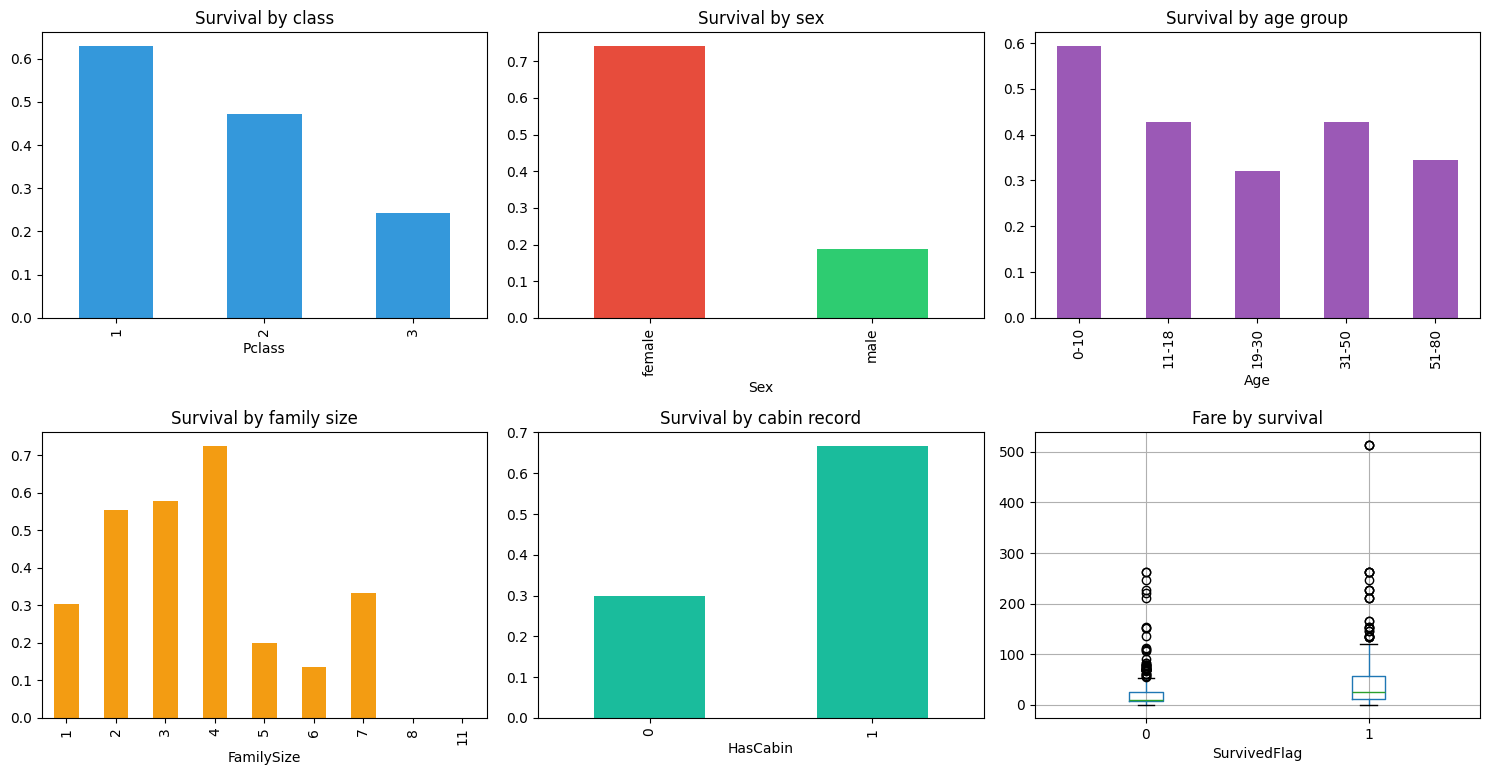

In [4]:
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
survived = (df["Survived"] == 1) | (df["Survived"] == "Yes") if df["Survived"].dtype == object else df["Survived"] == 1
df["SurvivedFlag"] = survived.astype(int)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

df.groupby("Pclass")["SurvivedFlag"].mean().plot(kind="bar", ax=axes[0,0], color="#3498db", title="Survival by class")
df.groupby("Sex")["SurvivedFlag"].mean().plot(kind="bar", ax=axes[0,1], color=["#e74c3c","#2ecc71"], title="Survival by sex")

age_bins = pd.cut(df["Age"], bins=[0,10,18,30,50,80], labels=["0-10","11-18","19-30","31-50","51-80"])
df.groupby(age_bins, observed=True)["SurvivedFlag"].mean().plot(kind="bar", ax=axes[0,2], color="#9b59b6", title="Survival by age group")

df.groupby("FamilySize")["SurvivedFlag"].mean().plot(kind="bar", ax=axes[1,0], color="#f39c12", title="Survival by family size")
df.groupby("HasCabin")["SurvivedFlag"].mean().plot(kind="bar", ax=axes[1,1], color="#1abc9c", title="Survival by cabin record")
df.boxplot(column="Fare", by="SurvivedFlag", ax=axes[1,2]); axes[1,2].set_title("Fare by survival"); plt.suptitle("")

for ax in axes.flat:
    ax.set_ylabel("")
plt.tight_layout()
plt.savefig("eda_summary.png", dpi=150)
plt.show()

1. **Class matters:** 1st class survived ~63%, 3rd class only ~24%.
2. **Sex is the strongest predictor:** women survived far more often than men.
3. **Children (0-10) had an edge** over other age groups.
4. **Family size has a sweet spot:** 2-4 members survived more than solo travellers or large families.
5. **Fare and cabin record correlate with survival**, mainly because both reflect passenger class.

## 5. Modeling

*(Full detail in Task 3: `SWYNEX-Modeling-and-Evaluation`.)* Based on the EDA, we select `Pclass`, `Sex`,
`Age`, `Fare`, `FamilySize`, `HasCabin` as features and train two baseline classifiers.

In [5]:
features = ["Pclass", "Sex", "Age", "Fare", "FamilySize", "HasCabin"]
X = df[features].copy()
X["Sex"] = X["Sex"].map({"male": 0, "female": 1})
y = df["SurvivedFlag"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

log_reg = LogisticRegression(random_state=42).fit(X_train_s, y_train)
rf = RandomForestClassifier(n_estimators=200, max_depth=5, random_state=42).fit(X_train, y_train)

y_pred_log, y_proba_log = log_reg.predict(X_test_s), log_reg.predict_proba(X_test_s)[:,1]
y_pred_rf, y_proba_rf = rf.predict(X_test), rf.predict_proba(X_test)[:,1]
print("Both models trained.")

Both models trained.


## 6. Evaluation

In [6]:
def evaluate(name, y_true, y_pred, y_proba):
    return {"Model": name, "Accuracy": accuracy_score(y_true,y_pred),
            "Precision": precision_score(y_true,y_pred), "Recall": recall_score(y_true,y_pred),
            "F1": f1_score(y_true,y_pred), "ROC-AUC": roc_auc_score(y_true,y_proba)}

results = pd.DataFrame([
    evaluate("Logistic Regression", y_test, y_pred_log, y_proba_log),
    evaluate("Random Forest", y_test, y_pred_rf, y_proba_rf),
]).set_index("Model").round(3)
results

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.799,0.754,0.710,0.731,0.842
Random Forest,0.793,0.758,0.681,0.718,0.839


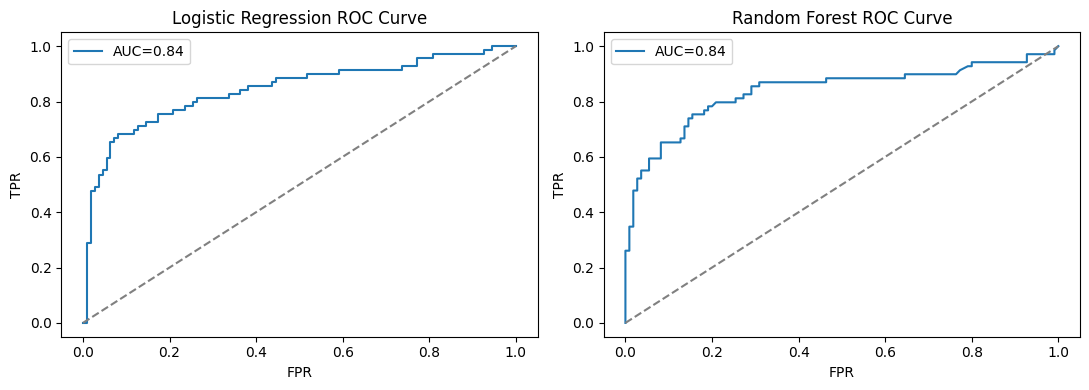

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11,4))
for ax, (name, proba) in zip(axes, [("Logistic Regression", y_proba_log), ("Random Forest", y_proba_rf)]):
    fpr, tpr, _ = roc_curve(y_test, proba)
    ax.plot(fpr, tpr, label=f"AUC={roc_auc_score(y_test, proba):.2f}")
    ax.plot([0,1],[0,1],'--',color='gray')
    ax.set_title(f"{name} ROC Curve"); ax.set_xlabel("FPR"); ax.set_ylabel("TPR"); ax.legend()
plt.tight_layout()
plt.savefig("final_roc_curves.png", dpi=150)
plt.show()

Both models reach roughly **80% accuracy** and **0.84 ROC-AUC**, clearly beating the majority-class baseline
of ~62% (always predicting "did not survive"). Logistic Regression and Random Forest perform almost identically,
suggesting the relationship between these features and survival is largely linear and additive.

## 7. Conclusions and Business Recommendations

**Key findings:**
- Sex, passenger class, age, and family size were the strongest predictors of survival.
- Fare and cabin record add little beyond what class already captures.
- A simple baseline model (Logistic Regression) performs essentially as well as a more complex Random Forest here,
  showing that added model complexity isn't always necessary.

**If this were a live decision-support tool** (e.g. for future safety planning), the clearest actionable insight
is that evacuation prioritization by class/location strongly affected outcomes — a finding relevant to modern
ship and building evacuation design, not just historical analysis.

**Limitations:**
- Small dataset (891 rows); a single train/test split can shift results — cross-validation would be more robust.
- Historical, non-representative data — 1912 patterns don't generalize to other contexts.
- Age/Cabin were partly imputed, adding some noise.
- Class imbalance (~38% survived) means accuracy alone is not a reliable metric.
- No hyperparameter tuning was performed; further gains are possible.

**Next steps:** cross-validation, hyperparameter tuning, and additional feature engineering (e.g. extracting
titles like "Mr/Mrs/Miss" from passenger names, which often correlates with age and class in other Titanic analyses).